# MFIN 4338 Empirical Methods in Finance: Problem Set 1

**Group number:** 15

| Afonso Vieira da Luz | 43337 |
| Florian Radlmeier | 43347 |
| Hannah Schmid | 96932 |
| Moritz Olbrich | 43352 |


# Set-up
We use pandas and numpy for the data, matplotlib for the plots, scipy for the distributions and tests, and statsmodels for the regressions. The two data files (`data_assignment1.xlsx` and `pension.dta`) should be in the same folder as this notebook, otherwise change `DATA_DIR` below.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import scipy.stats as stats

import statsmodels.api as sm
from statsmodels.api import OLS
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan

plt.style.use('seaborn-v0_8')
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
pd.set_option('display.width', 200)

DATA_DIR = '.'   # folder with the data files

---
# Question 1: Market indices, Coca-Cola, Microsoft and ExxonMobil

### 1 (a)
We read the sheet `stock_monthly` and use the date column as the index. We also rename the stock columns to their tickers (KO, MSFT, XOM) and put the two indices first, so that the order is the same in all tables below.

In [ ]:
ret = pd.read_excel(os.path.join(DATA_DIR, 'data_assignment1.xlsx'), sheet_name='stock_monthly', index_col='DATE')

# use tickers as column names and put the two indices first
ret = ret.rename(columns={'COCACOLA': 'KO', 'MICROSOFT': 'MSFT', 'EXXON': 'XOM'})
ret = ret[['VWRET', 'EWRET', 'KO', 'MSFT', 'XOM']]

print('Sample: {} to {}, {} months'.format(ret.index.min().date(), ret.index.max().date(), len(ret)))
print('Missing values:', ret.isna().sum().sum())
ret.head()

Sample: 1990-01-31 to 2024-12-31, 420 months
Missing values: 0


,VWRET,EWRET,KO,MSFT,XOM
DATE,,,,,
1990-01-31,-0.0701,-0.0464,-0.1084,0.0632,-0.0600
1990-02-28,0.0149,0.0154,0.0236,0.0676,0.0128
1990-03-30,0.0241,0.0213,0.0660,0.1215,-0.0186
1990-04-30,-0.0283,-0.0281,0.0201,0.0474,-0.0190
1990-05-31,0.0889,0.0457,0.1836,0.2586,0.0740


The data contain 420 monthly simple returns from January 1990 to December 2024 for the five series, with no missing values. The returns are in decimals (e.g. 0.063 = 6.3%).

### 1 (b)
The log (continuously compounded) return is
$$r_t = \ln(1 + R_t)$$
where $R_t$ is the simple return.

In [ ]:
# np.log1p(x) is simply log(1 + x), i.e. ln(1 + simple return) = log return
logret = np.log1p(ret)
logret.head()

Since $\ln(1+x) \le x$, the log return is always below the simple return. For small returns the two are almost equal ($\ln(1+R_t) \approx R_t$), and the gap grows with the size of the return.

### 1 (c)
For each series we plot the simple and the log return in the same graph, which gives five graphs.

In [ ]:
names = {'VWRET': 'Value-weighted index (VWRET)', 'EWRET': 'Equal-weighted index (EWRET)', 'KO': 'Coca-Cola (KO)', 'MSFT': 'Microsoft (MSFT)', 'XOM': 'ExxonMobil (XOM)'}

# NBER recession periods within the sample (shaded grey in the plots)
recessions = [('1990-07', '1991-03'), ('2001-03', '2001-11'), ('2007-12', '2009-06'), ('2020-02', '2020-04')]

fig, axes = plt.subplots(5, 1, figsize=(12, 18), sharex=True)
for ax, col in zip(axes, ret.columns):
    ax.plot(ret.index, ret[col], label='Simple return', color='tab:blue', linewidth=1.3)
    ax.plot(logret.index, logret[col], label='Log return', color='tab:red', linewidth=0.8)
    for start, end in recessions:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color='grey', alpha=0.25,
                   label='NBER recession' if start == recessions[0][0] else None)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(names[col])
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


In [ ]:
# annualized volatility of log returns in different sub-periods, to support the comments
periods = {'1990-97': ('1990', '1997'), '1998-02': ('1998', '2002'), '2003-07': ('2003', '2007'),
           '2008-09': ('2008', '2009'), '2010-19': ('2010', '2019'), '2020-24': ('2020', '2024')}
vol_periods = pd.DataFrame({p: logret.loc[a:b].std() * np.sqrt(12) for p, (a, b) in periods.items()})
print('Annualized volatility of log returns by sub-period:')
print((vol_periods * 100).round(1).to_string(float_format=lambda x: f'{x:.1f}%'))


# difference between simple and log returns, in percentage points
gap = (ret - logret) * 100
print('Simple minus log return (percentage points):')
print(pd.DataFrame({'Average gap': gap.mean(), 'Largest gap': gap.max(), 'Month of largest gap': gap.idxmax().dt.date}))

Annualized volatility of log returns by sub-period:
       1990-97  1998-02  2003-07  2008-09  2010-19  2020-24
VWRET    12.0%    20.1%     9.2%    25.8%    12.7%    18.6%
EWRET    14.4%    24.8%    13.2%    31.5%    13.9%    21.8%
KO       20.0%    30.2%    15.1%    23.2%    13.2%    19.0%
MSFT     28.5%    50.1%    19.4%    29.9%    20.9%    22.0%
XOM      12.3%    18.4%    17.0%    18.4%    16.8%    33.7%


**Simple vs. log returns.** In all five graphs the two lines are almost on top of each other. They only separate in the large months, and the log return is always the lower of the two. Because of the concavity of the log, the gap is bigger in crashes than in rallies of the same size: a −34% month becomes −42% in logs, while a +34% month would become +29%. So the log returns look a bit more negatively skewed than the simple returns.

**Over time and recessions.** None of the series has a visible trend. They move around a small positive mean, but the size of the swings changes over time (volatility clustering): calm periods (mid 1990s, 2003–2007, most of the 2010s) alternate with turbulent ones. The grey bands mark the NBER recessions (1990–91, 2001, 2007–09, 2020), and the biggest swings cluster in and around them:

* **1998–2002** (Russian default/LTCM, dot-com bubble and crash, with the 2001 recession at the end): the VW index's annualized volatility goes from 12% in 1990–97 to 20%, and Microsoft's to 50%. Microsoft has its worst month in April 2000 (log return −42%), before the recession, after the crash in tech stocks and the ruling in its antitrust case.
* **2008–2009** (financial crisis, inside the 2007–09 recession): the highest volatility of the indices (26% VW, 32% EW), with the worst VW month in October 2008 (−20%).
* **March 2020** (COVID, the short 2020 recession): the worst month for the EW index (−23%) and for ExxonMobil (−30%), followed by a sharp rebound in April 2020, which is the best month of the VW index.

**Differences between series.** The two indices are clearly smoother than the single stocks, because diversification removes most firm-specific shocks. Among the stocks, Microsoft is by far the most volatile, especially around 2000, and has absolute returns above 10% in 20% of the months. Coca-Cola's big moves are concentrated in 1997–1999. ExxonMobil follows oil prices rather than the recession dates: its volatility is highest in 2020–2024 (34%), with the COVID oil price collapse and then the 2022 energy rally (its best month is October 2022).


### 1 (d)

In [ ]:
corr = logret.corr()
display(corr.round(3))

# Heatmap of the same matrix: darker red = stronger positive correlation
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap='RdYlBu_r', vmin=0, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center',
                color='white' if corr.iloc[i, j] > 0.75 or corr.iloc[i, j] < 0.25 else 'black')
fig.colorbar(im, ax=ax, label='Correlation')
ax.set_title('Correlation matrix of monthly log returns')
plt.tight_layout()
plt.show()


All correlations are positive. Each stock is clearly correlated with both indices, but more with the value-weighted one:

| | VW index | EW index |
|---|---|---|
| Microsoft | 0.58 | 0.46 |
| ExxonMobil | 0.49 | 0.41 |
| Coca-Cola | 0.44 | 0.28 |

This makes sense. The VW index weights each stock by its market capitalization, so it is dominated by large firms like these three. They are themselves part of the index (Microsoft is one of its largest constituents for much of the sample), which mechanically raises the correlation. The EW index gives the same weight to every firm, so it is driven much more by the many small stocks, which behave differently from mega-caps. This is also why the two indices are highly but not perfectly correlated (0.875). Coca-Cola has the lowest correlation with the EW index (0.28). It is a large, stable consumer staples stock, which is quite different from the typical small firm.

The correlations between the three stocks are low (0.18 to 0.32). A large part of each stock's risk is firm-specific and can be diversified away, which is what we also saw in the smoother index plots in (c).

### 1 (e)
We plot each stock's log returns against the VW index. To make the slopes easier to compare, we add the OLS line and a 45-degree line (slope of one, i.e. moving one-for-one with the market). All axes use the same scale.

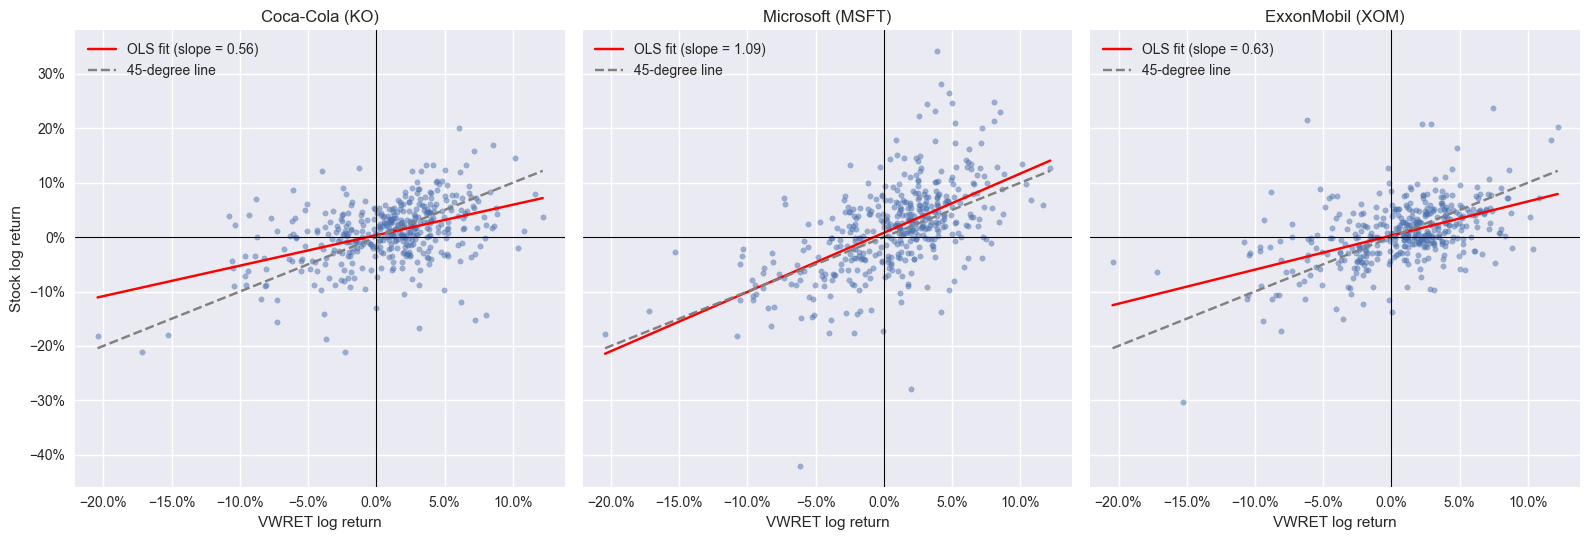

In [ ]:
stocks = ['KO', 'MSFT', 'XOM']
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharex=True, sharey=True)
x_grid = np.linspace(logret['VWRET'].min(), logret['VWRET'].max(), 100)

for ax, s in zip(axes, stocks):
    ax.scatter(logret['VWRET'], logret[s], alpha=0.5, s=15)
    slope, intercept = np.polyfit(logret['VWRET'], logret[s], 1)   # OLS fit, only for the plot
    ax.plot(x_grid, intercept + slope * x_grid, color='red', label=f'OLS fit (slope = {slope:.2f})')
    ax.plot(x_grid, x_grid, color='grey', linestyle='--', label='45-degree line')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(names[s])
    ax.set_xlabel('VWRET log return')
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.legend(loc='upper left')
axes[0].set_ylabel('Stock log return')
plt.tight_layout()
plt.show()

All three clouds slope upwards, so the stocks tend to go up when the market goes up, in line with the positive correlations in (d). There are two clear differences between the stocks:

* **Slope.** Microsoft's cloud is the steepest and close to the 45-degree line (slope 1.09), so it moves about one-for-one with the market. Coca-Cola (0.56) and ExxonMobil (0.63) are much flatter, so they react less to market movements. These are the defensive stocks one would expect: soft drinks and energy are needed in good and bad times.
* **Dispersion.** In all three graphs the points are widely scattered around the line, so the market explains only a small part of the stock returns. The dispersion is largest for Microsoft, which also has a lot of firm-specific risk. We can see a few clear outliers that have little to do with the market, such as Microsoft's −42% in April 2000 and Coca-Cola's large moves around 1998–1999.

The slopes in these graphs are the CAPM betas that we estimate formally in (i).

### 1 (f)
We use the sample variance (with $T-1$), and the skewness and excess kurtosis from `scipy.stats` (`kurtosis` gives excess kurtosis by default, i.e. kurtosis minus 3).

In [ ]:
summary = pd.DataFrame({
    'Mean': logret.mean(),
    'Variance': logret.var(),
    'Std. dev.': logret.std(),
    'Skewness': logret.apply(stats.skew),
    'Excess kurtosis': logret.apply(stats.kurtosis),   #fisher=True by default -> excess kurtosis
    'Min': logret.min(),
    'Max': logret.max(),
})
print('Monthly log returns:')
print(summary.round(4))

#annualized figures and the mean/std ratio make the comparison easier
annual = pd.DataFrame({
    'Mean (ann.)': logret.mean() * 12,
    'Std. dev. (ann.)': logret.std() * np.sqrt(12),
    'Mean / Std. dev. (monthly)': logret.mean() / logret.std(),
    'Month of min': logret.idxmin().dt.date,
    'Month of max': logret.idxmax().dt.date,
})
print('\nAnnualized:')
print(annual)

Monthly log returns:
        Mean  Variance  Std. dev.  Skewness  Excess kurtosis     Min    Max
VWRET 0.0080    0.0020     0.0444   -0.8299           1.8272 -0.2044 0.1219
EWRET 0.0082    0.0028     0.0530   -0.5769           2.7840 -0.2326 0.2030
KO    0.0080    0.0033     0.0570   -0.5666           1.8697 -0.2119 0.2011
MSFT  0.0167    0.0071     0.0840   -0.1146           2.4784 -0.4209 0.3420
XOM   0.0079    0.0032     0.0569   -0.0931           3.6548 -0.3036 0.2384

Annualized:
       Mean (ann.)  Std. dev. (ann.)  Mean / Std. dev. (monthly) Month of min Month of max
VWRET       0.0962            0.1537                      0.1807   2008-10-31   2020-04-30
EWRET       0.0988            0.1837                      0.1552   2020-03-31   2001-01-31
KO          0.0966            0.1975                      0.1412   1998-08-31   1999-10-29
MSFT        0.2010            0.2909                      0.1994   2000-04-28   2001-01-31
XOM         0.0951            0.1971                   

Comparing the two indices:

| | VW index | EW index |
|---|---|---|
| Mean (monthly) | 0.80% | 0.82% |
| Variance | 0.0020 | 0.0028 |
| Std. dev. (annualized) | 15.4% | 18.4% |
| Skewness | −0.83 | −0.58 |
| Excess kurtosis | 1.83 | 2.78 |
| Min | −20.4% (Oct 2008) | −23.3% (Mar 2020) |
| Max | 12.2% (Apr 2020) | 20.3% (Jan 2001) |

* **Mean.** The average returns are almost the same, 0.80% per month for VW and 0.82% for EW (9.6% vs 9.9% per year).
* **Variance.** The EW index has a variance about 40% higher (0.0028 vs 0.0020), i.e. an annualized volatility of 18.4% vs 15.4%.
* **Skewness.** Both distributions are negatively skewed, so large losses are more common than large gains of the same size. The VW index is the more negatively skewed of the two (−0.83 vs −0.58).
* **Kurtosis.** Both have fat tails (positive excess kurtosis), and the EW index's tails are fatter (2.78 vs 1.83).
* **Min and max.** The EW index has both the worst month (−23.3%) and the best month (+20.3% in January 2001, when small stocks rallied strongly). Its range is much wider than VW's (−20.4% to +12.2%).

**From an investment perspective, the EW index carries more risk.** It has a higher volatility, fatter tails and a worse worst month, while its average return is almost the same. Per unit of risk it is therefore less attractive: the ratio of mean to standard deviation is 0.18 for VW and 0.15 for EW. The reason is that the EW index puts much more weight on small firms, which are more volatile and more sensitive to bad times than the large firms that dominate the VW index. The only measure that points the other way is skewness, since VW's distribution leans a bit more to the downside. But in absolute terms the losses of the EW index are still larger, so this does not change the conclusion.

As expected, the single stocks are riskier than both indices, with annualized volatilities of 20% (KO and XOM) and 29% (MSFT). Microsoft has the highest mean (1.67% per month, 20% per year), but also the highest volatility and the worst month in the sample (−42%). ExxonMobil has the fattest tails (excess kurtosis 3.65).

### 1 (g)
For each series we test $H_0: \mu = 0$ against $H_1: \mu \neq 0$ with the t-statistic
$$t = \frac{\bar r}{s / \sqrt{T}} \sim t_{T-1}$$
using `scipy.stats.ttest_1samp`, which is two-sided by default.

In [ ]:
alpha_level = 0.05
ttests = {}
for col in logret.columns:
    res = stats.ttest_1samp(logret[col], popmean=0)   #two-sided by default
    ttests[col] = {'Mean': logret[col].mean(),
                   'Std. error': logret[col].std() / np.sqrt(len(logret)),
                   't-stat': res.statistic,
                   'p-value': res.pvalue,
                   'Reject H0 at 5%': res.pvalue < alpha_level}
ttests = pd.DataFrame(ttests).T
print('Critical value (two-sided, 5%): {:.3f}'.format(stats.t.ppf(0.975, df=len(logret) - 1)))
ttests

Critical value (two-sided, 5%): 1.966


,Mean,Std. error,t-stat,p-value,Reject H0 at 5%
VWRET,0.0080,0.0022,3.7031,0.0002,True
EWRET,0.0082,0.0026,3.1815,0.0016,True
KO,0.0080,0.0028,2.8927,0.0040,True
MSFT,0.0167,0.0041,4.0874,0.0001,True
XOM,0.0079,0.0028,2.8554,0.0045,True


The t-statistics range from 2.86 (XOM) to 4.09 (MSFT), all above the 5% critical value of 1.97, and all p-values are below 0.5%. **We reject the null of a zero mean return for all five series.** Over 1990–2024 the average monthly log return was significantly positive for both indices and the three stocks, so investors were on average compensated for holding them.

Two comments on this result:

* The test assumes independent returns, and with $T = 420$ the t-distribution is a good approximation through the CLT even though returns are not normal (see (h)). Monthly returns have very little autocorrelation, so this seems reasonable.
* The result depends a lot on the long sample. The means are small compared with the volatility (between 0.14 and 0.20 standard deviations per month), and the t-statistic grows with $\sqrt{T}$. With only five years of data, the t-statistic of the VW index would be about $3.70 \times \sqrt{60/420} \approx 1.40$, and we would no longer reject. This is why expected returns are so hard to estimate precisely in finance.

### 1 (h)
We plot a histogram of each series together with the Normal density with the same mean and standard deviation (solid line). We then run the Jarque–Bera test, which uses skewness ($S$) and excess kurtosis ($K$):
$$JB = \frac{T}{6}\left(S^2 + \frac{K^2}{4}\right) \sim \chi^2_2 \text{ under } H_0: \text{normality}$$
We come back to the dashed line (a fitted Student-t) at the end of this question.

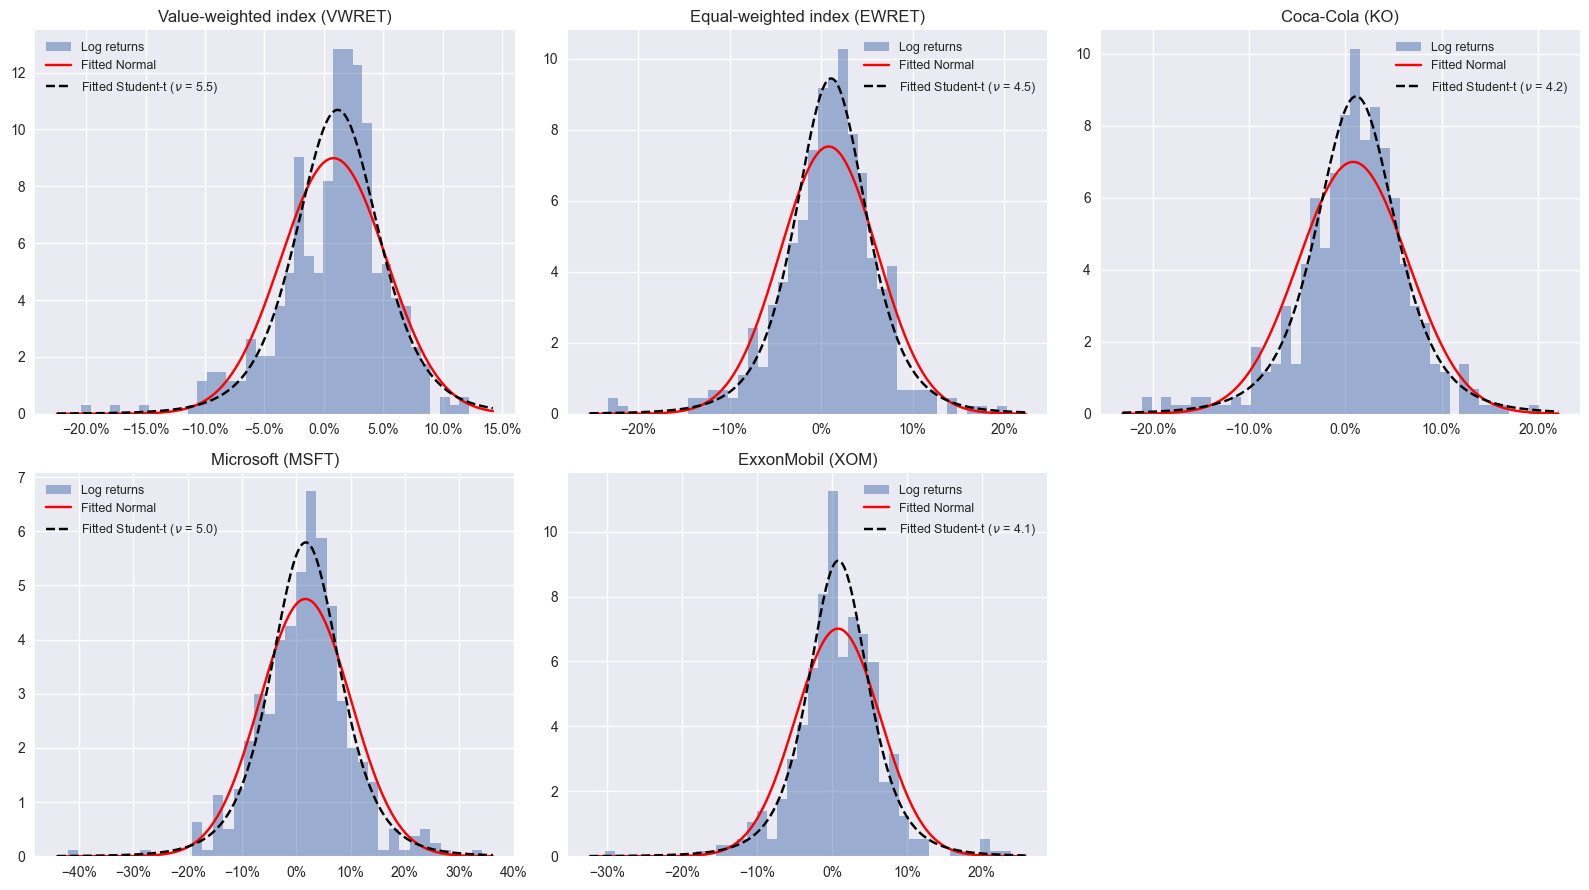

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, logret.columns):
    x = logret[col]
    grid = np.linspace(x.min() - 0.02, x.max() + 0.02, 300)
    ax.hist(x, bins=40, density=True, alpha=0.5, label='Log returns')
    #Normal with the sample mean and standard deviation
    ax.plot(grid, stats.norm.pdf(grid, loc=x.mean(), scale=x.std()), color='red', label='Fitted Normal')
    #Student-t fitted by maximum likelihood (degrees of freedom, location, scale)
    nu, loc, scale = stats.t.fit(x)
    ax.plot(grid, stats.t.pdf(grid, nu, loc, scale), color='black', linestyle='--',
            label=f'Fitted Student-t ($\\nu$ = {nu:.1f})')
    ax.set_title(names[col])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.legend(fontsize=9)

axes[-1].axis('off')   #only five series, hide the sixth panel
plt.tight_layout()
plt.show()

In [ ]:
jb_res = {}
for col in logret.columns:
    jb_stat, jb_p, skew, kurt = jarque_bera(logret[col])   #kurt here is the raw kurtosis (not excess)
    jb_res[col] = {'Skewness': skew, 'Excess kurtosis': kurt - 3, 'JB stat': jb_stat,
                   'p-value': jb_p, 'Reject normality at 5%': jb_p < 0.05,
                   'Student-t dof': stats.t.fit(logret[col])[0]}
jb_res = pd.DataFrame(jb_res).T
print('Critical value chi2(2), 5%: {:.2f}'.format(stats.chi2.ppf(0.95, df=2)))
jb_res.sort_values('JB stat')

Critical value chi2(2), 5%: 5.99


,Skewness,Excess kurtosis,JB stat,p-value,Reject normality at 5%,Student-t dof
KO,-0.5666,1.8697,83.6492,0.0000,True,4.2268
VWRET,-0.8299,1.8272,106.6334,0.0000,True,5.4603
MSFT,-0.1146,2.4784,108.4159,0.0000,True,4.9544
EWRET,-0.5769,2.7840,158.9288,0.0000,True,4.4913
XOM,-0.0931,3.6548,234.3667,0.0000,True,4.0826


**The log returns do not look Normal.** In all five histograms there are more observations close to the mean than the Normal predicts (the peak is higher and narrower), fewer in the shoulders, and more in the tails. There are also a few extreme months on the left, like October 2008 and March 2020, that would be almost impossible under a Normal. With a monthly standard deviation of 4.4%, the −20.4% of the VW index is a 4.8 standard deviation event. This matches the summary statistics in (f): negative skewness and positive excess kurtosis everywhere.

**Indices vs. stocks.** One might expect the indices to be closer to Normal, since they average many stocks and the CLT should work in their favour. The data only partly support this:

* The VW index has one of the lowest excess kurtosis values (1.83, similar to KO's 1.87), but it is also the most negatively skewed series (−0.83). The EW index is further from Normal than VW (kurtosis 2.78).
* Microsoft and ExxonMobil are almost symmetric (skewness around −0.1), but have fat tails, especially XOM (3.65).

The reason is that the CLT argument requires the stocks to be roughly independent, and they are not. Diversification removes firm-specific shocks, but market-wide crashes hit all stocks at the same time and stay in the index. This is where the negative skewness of the indices comes from. For single stocks, firm-specific news (good and bad) makes the distribution more symmetric, but with fat tails.

**Jarque–Bera.** The JB statistics go from 84 (KO) to 234 (XOM), far above the 5% critical value of 5.99, and all p-values are essentially zero. **We reject normality for all five series.** Ranked by JB, Coca-Cola is closest to Normal, followed by the VW index and Microsoft (107 and 108), and the EW index (159) and ExxonMobil (234) are furthest away. So there is no clear ranking where indices are closer to Normal than individual stocks.

**A better distribution.** Since the main problem is fat tails, a Student-t distribution with few degrees of freedom is a natural alternative. Fitting it by maximum likelihood gives between 4.1 (XOM) and 5.5 (VW) degrees of freedom, far from the Normal limit ($\nu \to \infty$). The dashed lines in the histograms show that the t captures the high peak and the fat tails much better than the Normal. It is still symmetric, so a skewed Student-t (or a mixture of two Normals, one for calm and one for turbulent months) would also capture the negative skewness, which matters most for the indices.

### 1 (i)
With a risk-free rate of zero, the CAPM regression for stock $i$ is
$$r_{i,t} = \alpha_i + \beta_i\, r_{VW,t} + \varepsilon_{i,t}$$
We estimate it by OLS for each stock. Under the CAPM, $\alpha_i = 0$. We also test $H_0: \beta_i = 1$, i.e. whether the stock is as risky as the market.

In [ ]:
X = sm.add_constant(logret['VWRET'])

capm = {}
capm_table = {}
for s in stocks:
    res = OLS(logret[s], X).fit()
    capm[s] = res
    print('=' * 30, names[s], '=' * 30)
    print(res.summary().tables[1])

    beta, se_beta = res.params['VWRET'], res.bse['VWRET']
    t_beta1 = (beta - 1) / se_beta                              # test beta = 1
    capm_table[s] = {
        'Alpha (monthly)': res.params['const'],
        't (alpha = 0)': res.tvalues['const'],
        'p (alpha = 0)': res.pvalues['const'],
        'Alpha (annualized)': 12 * res.params['const'],
        'Beta': beta,
        't (beta = 0)': res.tvalues['VWRET'],
        't (beta = 1)': t_beta1,
        'p (beta = 1)': 2 * stats.t.sf(abs(t_beta1), df=res.df_resid),
        'R-squared': res.rsquared,
    }

capm_table = pd.DataFrame(capm_table)
capm_table

============================== Coca-Cola (KO) ==============================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0036      0.003      1.396      0.163      -0.001       0.009
VWRET          0.5601      0.057      9.902      0.000       0.449       0.671
============================== Microsoft (MSFT) ==============================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0080      0.003      2.352      0.019       0.001       0.015
VWRET          1.0886      0.076     14.377      0.000       0.940       1.237
============================== ExxonMobil (XOM) ==============================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------

,KO,MSFT,XOM
Alpha (monthly),0.0036,0.0080,0.0029
t (alpha = 0),1.3963,2.3518,1.1780
p (alpha = 0),0.1634,0.0191,0.2395
Alpha (annualized),0.0427,0.0962,0.0348
Beta,0.5601,1.0886,0.6267
t (beta = 0),9.9024,14.3765,11.4526
t (beta = 1),-7.7776,1.1700,-6.8211
p (beta = 1),0.0000,0.2427,0.0000
R-squared,0.1900,0.3309,0.2388


In [ ]:
# robustness: same regressions with heteroskedasticity-robust (White) standard errors
robust_t = pd.DataFrame({s: OLS(logret[s], X).fit(cov_type='HC1').tvalues for s in stocks})
robust_t.index = ['t alpha (robust)', 't beta (robust)']
robust_t

,KO,MSFT,XOM
t alpha (robust),1.3790,2.3646,1.1056
t beta (robust),7.7672,13.9739,8.0768


| | Coca-Cola | Microsoft | ExxonMobil |
|---|---|---|---|
| $\hat\alpha$ (monthly) | 0.36% (t = 1.40) | 0.80% (t = 2.35) | 0.29% (t = 1.18) |
| $\hat\alpha$ (annualized) | 4.3% | 9.6% | 3.5% |
| $\hat\beta$ | 0.56 (t = 9.90) | 1.09 (t = 14.38) | 0.63 (t = 11.45) |
| t-stat, $H_0: \beta = 1$ | −7.78 | 1.17 | −6.82 |
| $R^2$ | 0.19 | 0.33 | 0.24 |

**Betas.** All three betas are positive and highly significant (t-statistics between 9.9 and 14.4), so market risk clearly matters for all three stocks.

* **Coca-Cola** ($\beta = 0.56$) and **ExxonMobil** ($\beta = 0.63$) are defensive stocks. When the market goes up or down by 1%, they move on average by only about 0.6%. Both betas are significantly below one (t = −7.78 and −6.82), so this is not just noise. This fits their businesses, since demand for soft drinks and energy depends little on the business cycle.
* **Microsoft** ($\beta = 1.09$) moves roughly one-for-one with the market. The beta is slightly above one, but the difference is not significant (t = 1.17, p = 0.24), so we cannot distinguish it from the market's beta.

**Alphas.** Under the CAPM all alphas should be zero.

* For **Coca-Cola** and **ExxonMobil** the alphas are not significant (p = 0.16 and 0.24), even though they look large economically (4.3% and 3.5% per year). The returns of these two stocks are consistent with the CAPM.
* **Microsoft** has an alpha of 0.80% per month (9.6% per year), which is significant at 5% (t = 2.35, p = 0.019). Economically this is very large: after adjusting for market risk, Microsoft beat the market by almost 10% per year over 35 years.

**Statistical vs. economic significance.** The alphas show how imprecise these estimates are. An alpha of 4% per year is large for an investor, but with this much idiosyncratic risk we cannot reject that it is zero. The $R^2$ values are low (0.19 to 0.33), so the market explains only a small part of the stock returns and 67% to 81% of the variance is firm-specific.

We should also be careful with the results for three reasons:

* **Risk-free rate.** Setting $r_f = 0$ biases the alpha. The correct model is $r_i - r_f = \alpha^* + \beta (r_{VW} - r_f)$, so the alpha we estimate is $\alpha = \alpha^* + (1-\beta)\, r_f$. With T-bill rates of a few percent per year on average over the sample, the alphas of the low-beta stocks KO and XOM are overstated by about 40% of the risk-free rate. Microsoft's alpha is almost unaffected, since its beta is close to one.
* **Stock selection.** We know today that Microsoft became one of the largest companies in the world, so picking it for the analysis already selects a winner. Its alpha says more about the past than about what we could have expected in 1990.
* **Standard errors.** With heteroskedasticity-robust (White) standard errors the beta t-statistics become somewhat smaller (7.8 to 14.0) but stay very large, and Microsoft's alpha remains significant (t = 2.37). The conclusions do not change.

---
# Question 2: Net financial wealth and pension data

### 2 (a)
We read the Stata file with `pd.read_stata`. The variables are stored as small integer types (`age` and `fsize` are `int8`). This matters for the regressions with squared terms: $64^2 = 4096$ does not fit in an `int8`, so `age**2` would silently overflow and give wrong numbers. We therefore convert all variables to 64-bit floats right after loading.

In [ ]:
pension = pd.read_stata(os.path.join(DATA_DIR, 'pension.dta'))
print('Original data types:')
print(pension.dtypes.to_string())

# convert everything to float64 to avoid integer overflow when squaring (e.g. age is int8)
pension = pension.astype('float64')

print('\nObservations: {}'.format(len(pension)))
pension[['nettfa', 'inc', 'age', 'fsize']].describe().T

Original data types:
e401k        int8
inc       float32
marr         int8
male         int8
age          int8
fsize        int8
nettfa    float32
p401k        int8
pira         int8
incsq     float32
agesq       int16

Observations: 9275


,count,mean,std,min,25%,50%,75%,max
nettfa,9275.0000,19.0717,63.9638,-502.3020,-0.5000,2.0000,18.4495,1536.7980
inc,9275.0000,39.2546,24.0900,10.0080,21.6600,33.2880,50.1600,199.0410
age,9275.0000,41.0802,10.2995,25.0000,33.0000,40.0000,48.0000,64.0000
fsize,9275.0000,2.8851,1.5258,1.0000,2.0000,3.0000,4.0000,13.0000


There are 9,275 households. Net financial wealth is very unequal: the median is only 2,000 USD, while the mean is 19,100 USD, and the largest value is over 1.5 million USD. About 29% of households have negative net financial wealth.

### 2 (b)
Single-person households are the households with `fsize` = 1.

In [ ]:
single = pension[pension['fsize'] == 1].copy()

n_single = len(single)
share_single = n_single / len(pension)
print('Single-person households: {}'.format(n_single))
print('Share of the full sample: {:.1%}'.format(share_single))

Single-person households: 2017
Share of the full sample: 21.7%


There are **2,017 single-person households**, which is **21.7%** of the 9,275 households in the sample. We use this sub-sample for the "single-head households" in (c) to (g) and (l).

### 2 (c)

In [ ]:
model1 = OLS.from_formula('nettfa ~ inc + age', data=single).fit()
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:                 nettfa   R-squared:                       0.119
Model:                            OLS   Adj. R-squared:                  0.118
Method:                 Least Squares   F-statistic:                     136.5
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           2.63e-56
Time:                        10:31:29   Log-Likelihood:                -10524.
No. Observations:                2017   AIC:                         2.105e+04
Df Residuals:                    2014   BIC:                         2.107e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -43.0398      4.080    -10.548      0.0

The estimated equation is

$$\widehat{nettfa} = \underset{(4.08)}{-43.04} + \underset{(0.060)}{0.799}\, inc + \underset{(0.092)}{0.843}\, age, \qquad n = 2{,}017, \quad R^2 = 0.119$$

with standard errors in parentheses. Since both variables are in thousands of USD:

* **Income.** Holding age fixed, 1,000 USD more annual income is associated with about **799 USD more net financial wealth** on average. Higher earners can save more, so they accumulate more wealth.
* **Age.** Holding income fixed, one more year of age is associated with about **843 USD more net financial wealth**. Older people have had more years to save, so this is in line with life-cycle saving.

**Both effects are highly statistically significant**, with t-statistics of 13.38 (income) and 9.16 (age) and p-values close to zero. The $R^2$ is only 0.119 though, so income and age explain about 12% of the variation in wealth. This is not surprising for a variable as unequal as wealth, which also depends on inheritances, preferences and many other factors.

### 2 (d)

In [ ]:
# checking data range of single households
display(single[["age", "inc"]].agg(["min", "max"]))

# Predicted net wealth (in $1,000) for a 25-year-old single at different income levels
model1.predict(pd.DataFrame({"age": 25, "inc": [10, 20, 27.5, 40]}))

# Income at which predicted net wealth = 0 for age 25
b = model1.params
-(b["Intercept"] + b["age"] * 25) / b["inc"]

The intercept (−43.04) is the predicted net financial wealth of a single household with zero income and age zero, i.e. about −$43,000. It has no meaningful interpretation: no one in the sample is younger than 25, so this is an extrapolation far outside the range of the data, and a newborn with $43,000 of debt is not an economically sensible scenario. The intercept mainly serves to position the regression line so that it fits the data well within the observed range. A more informative quantity is a prediction within that range: for a 25-year-old, the model predicts negative net wealth for incomes below about $27,500, consistent with young, low-income households having accumulated little or no financial wealth.

### 2 (e)
We test $H_0: \beta_2 = 1$ against $H_1: \beta_2 < 1$ with

$$t = \frac{\hat\beta_2 - 1}{se(\hat\beta_2)} \sim t_{n-3}$$

Since the alternative is one-sided (left tail), the p-value is $P(t_{n-3} < t)$.

In [ ]:
b2 = model1.params['age']
se_b2 = model1.bse['age']
df_resid = model1.df_resid

t_stat = (b2 - 1) / se_b2
p_one_sided = stats.t.cdf(t_stat, df=df_resid)   # left tail: H1 is beta_2 < 1
crit_one_sided = stats.t.ppf(0.05, df=df_resid)

print('beta_2 = {:.4f}, se = {:.4f}'.format(b2, se_b2))
print('t-statistic: {:.3f}'.format(t_stat))
print('One-sided p-value: {:.4f}'.format(p_one_sided))
print('5% critical value (left tail): {:.3f}'.format(crit_one_sided))

beta_2 = 0.8427, se = 0.0920
t-statistic: -1.710
One-sided p-value: 0.0437
5% critical value (left tail): -1.646


$$t = \frac{0.8427 - 1}{0.0920} = -1.71$$

The one-sided **p-value is 0.044**. Since this is below 5% (equivalently, $t = -1.71$ is below the critical value of −1.646), **we reject $H_0$ at the 5% level**, in favour of an age effect below 1.

**Economic interpretation.** $\beta_2 = 1$ means that each extra year of age adds 1,000 USD to net financial wealth, for a given income. The test asks whether single people accumulate less than 1,000 USD of financial wealth per year of age, and the data say yes, although only marginally. The interpretation is clear, but the value of 1,000 USD is a round benchmark rather than something that comes from theory, so the test is only interesting if one has a reason to care about this particular number.

### 2 (f)

In [ ]:
p_two_sided = 2 * stats.t.cdf(-abs(t_stat), df=df_resid)
crit_two_sided = stats.t.ppf(0.975, df=df_resid)

print('t-statistic: {:.3f}'.format(t_stat))
print('Two-sided p-value: {:.4f}'.format(p_two_sided))
print('5% critical values: +/- {:.3f}'.format(crit_two_sided))
print('95% confidence interval for beta_2:', model1.conf_int().loc['age'].round(3).tolist())

# same test with statsmodels, as a check
print(model1.t_test('age = 1'))

t-statistic: -1.710
Two-sided p-value: 0.0874
5% critical values: +/- 1.961
95% confidence interval for beta_2: [0.662, 1.023]
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.8427      0.092     -1.710      0.087       0.662       1.023


The t-statistic is the same (−1.71), but the two-sided **p-value doubles to 0.087**. Since this is above 5% (and $|t| = 1.71 < 1.961$), **we do not reject $H_0$ at the 5% level**. The 95% confidence interval for $\beta_2$, [0.662, 1.023], includes one.

**Comparison with (e).** The two-sided test asks whether the age effect is different from 1,000 USD per year in either direction. Wealth growing faster than 1,000 USD per year also counts as evidence against $H_0$, so the 5% rejection region is split between the two tails, and we need stronger evidence on the downside to reject.

The conclusion changes from (e) to (f) only because the result is borderline: the p-value is between 2.5% and 5% for the one-sided test. The one-sided test is only valid if we had decided on the direction before looking at the estimate, i.e. if there was a theoretical reason to expect an effect below 1,000 USD. Otherwise, the more conservative two-sided test is the right one, and we cannot say that the age effect differs from 1,000 USD per year.

### 2 (g)

In [ ]:
model1_simple = OLS.from_formula('nettfa ~ inc', data=single).fit()
print(model1_simple.summary().tables[1])

# omitted variable bias: regress the omitted variable (age) on the included one (inc)
aux = OLS.from_formula('age ~ inc', data=single).fit()
delta = aux.params['inc']

b1_multiple = model1.params['inc']
b1_simple = model1_simple.params['inc']

print('\nIncome coefficient, multiple regression (c): {:.4f}'.format(b1_multiple))
print('Income coefficient, simple regression (g):   {:.4f}'.format(b1_simple))
print('Slope of age on inc (delta):                  {:.4f}'.format(delta))
print('beta_1 + beta_2 * delta:                      {:.4f}'.format(b1_multiple + model1.params['age'] * delta))
print('Correlation between inc and age:              {:.4f}'.format(single['inc'].corr(single['age'])))
print('R-squared: {:.3f} (simple) vs {:.3f} (multiple)'.format(model1_simple.rsquared, model1.rsquared))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -10.5710      2.061     -5.130      0.000     -14.612      -6.530
inc            0.8207      0.061     13.476      0.000       0.701       0.940

Income coefficient, multiple regression (c): 0.7993
Income coefficient, simple regression (g):   0.8207
Slope of age on inc (delta):                  0.0254
beta_1 + beta_2 * delta:                      0.8207
Correlation between inc and age:              0.0391
R-squared: 0.083 (simple) vs 0.119 (multiple)


Without age, the income coefficient is **0.821** instead of 0.799, so it is only slightly higher (by 0.021). The difference is the omitted variable bias. When we leave out age, the income coefficient also picks up part of the age effect:

$$\tilde\beta_1 = \hat\beta_1 + \hat\beta_2\, \tilde\delta_1 = 0.7993 + 0.8427 \times 0.0254 = 0.8207$$

where $\tilde\delta_1 = 0.0254$ is the slope from regressing age on income. The bias is positive because age has a positive effect on wealth ($\hat\beta_2 > 0$) and older people tend to earn slightly more ($\tilde\delta_1 > 0$). It is small because, among single-person households, income and age are almost uncorrelated (correlation of 0.04). So leaving out age hardly affects the income estimate here, even though age itself is an important explanatory variable (the $R^2$ falls from 0.119 to 0.083).

### 2 (h)
We now use the full sample. The squared terms are created in the formula with `I()`.

In [ ]:
formula2 = 'nettfa ~ inc + age + I(inc**2) + I(age**2) + fsize'
model2 = OLS.from_formula(formula2, data=pension).fit()
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                 nettfa   R-squared:                       0.199
Model:                            OLS   Adj. R-squared:                  0.199
Method:                 Least Squares   F-statistic:                     460.4
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:31:29   Log-Likelihood:                -50700.
No. Observations:                9275   AIC:                         1.014e+05
Df Residuals:                    9269   BIC:                         1.015e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      13.9926      9.992      1.400      

In [ ]:
b = model2.params
b_inc, b_inc2 = b['inc'], b['I(inc ** 2)']
b_age, b_age2 = b['age'], b['I(age ** 2)']

# marginal effects: d nettfa / d inc = b_inc + 2*b_inc2*inc, d nettfa / d age = b_age + 2*b_age2*age
age_turn = -b_age / (2 * b_age2)
inc_turn = -b_inc / (2 * b_inc2)
print('Age at which the age effect turns positive: {:.1f} years'.format(age_turn))
print('Income at which the income effect turns positive: {:.2f} (thousand USD)'.format(inc_turn))
print('Age range in sample: {:.0f} to {:.0f}'.format(pension['age'].min(), pension['age'].max()))
print('Income range in sample: {:.2f} to {:.2f}'.format(pension['inc'].min(), pension['inc'].max()))

print('\nMarginal effect of one more year of age (thousand USD):')
for a in [25, 30, 40, 50, 60]:
    print('  age {}: {:.3f}'.format(a, b_age + 2 * b_age2 * a))

print('\nMarginal effect of 1,000 USD more income (thousand USD):')
for i in [10, 20, pension['inc'].mean(), 60, 100]:
    print('  income {:.1f}: {:.3f}'.format(i, b_inc + 2 * b_inc2 * i))

Age at which the age effect turns positive: 23.8 years
Income at which the income effect turns positive: 6.67 (thousand USD)
Age range in sample: 25 to 64
Income range in sample: 10.01 to 199.04

Marginal effect of one more year of age (thousand USD):
  age 25: 0.061
  age 30: 0.325
  age 40: 0.852
  age 50: 1.380
  age 60: 1.907

Marginal effect of 1,000 USD more income (thousand USD):
  income 10.0: 0.063
  income 20.0: 0.253
  income 39.3: 0.618
  income 60.0: 1.012
  income 100.0: 1.771


The estimated equation (standard errors in parentheses) is

$$\widehat{nettfa} = \underset{(9.99)}{13.99} \underset{(0.073)}{- 0.127}\, inc \underset{(0.492)}{- 1.258}\, age + \underset{(0.0006)}{0.0095}\, inc^2 + \underset{(0.0057)}{0.0264}\, age^2 \underset{(0.401)}{- 1.979}\, fsize$$

with $n = 9{,}275$ and $R^2 = 0.199$. With the squared terms, the coefficients on income and age can no longer be read alone, because the effect of each variable depends on its level:

$$\frac{\partial\, nettfa}{\partial\, inc} = -0.127 + 2(0.0095)\, inc, \qquad \frac{\partial\, nettfa}{\partial\, age} = -1.258 + 2(0.0264)\, age$$

**Income.** The negative linear term does not mean that income lowers wealth. The effect of income is increasing in income (convex), and it is negative only below 6,700 USD, which is under the lowest income in the sample (10,000 USD). So for everyone in the data, more income means more wealth, and the effect grows with income. 1,000 USD more income increases net financial wealth by about 250 USD at an income of 20,000 USD, 620 USD at the mean income (39,250 USD), and 1,770 USD at 100,000 USD. Richer households save a larger share of each extra dollar.

**Age.** The age effect is also convex. One more year of age increases wealth by only about 60 USD at age 25, but by 850 USD at 40 and 1,900 USD at 60. This is in line with the life cycle: people save more in the second half of their working life, when their income is higher and their expenses are lower, and their savings also earn returns for longer.

**For which individuals does age have a positive effect?** The effect of age is positive for everyone older than

$$age^* = \frac{1.258}{2 \times 0.0264} \approx 23.8 \text{ years}$$

Since the youngest person in the sample is 25, **age has a positive effect on net wealth for all individuals in the sample**. The decreasing part of the parabola (below about 24) lies outside the data and only comes from the quadratic functional form, so we would not interpret it.

**Family size.** Holding income and age fixed, each additional family member lowers net financial wealth by about **1,980 USD**. The effect is significant (t = −4.93). Larger families have higher expenses (children, housing, education) for the same income, so they save less.

### 2 (i)
We test the joint restriction $H_0: \beta_3 = \beta_4 = 0$ with an F-test:
$$F = \frac{(SSR_r - SSR_{ur})/q}{SSR_{ur}/(n-k-1)} \sim F_{q,\, n-k-1}, \qquad q = 2$$

In [ ]:
f_test = model2.f_test('I(inc ** 2) = 0, I(age ** 2) = 0')
print(f_test)

# the same F-statistic by hand, from the restricted and unrestricted SSR
model2_restricted = OLS.from_formula('nettfa ~ inc + age + fsize', data=pension).fit()
q = 2
F_manual = ((model2_restricted.ssr - model2.ssr) / q) / (model2.ssr / model2.df_resid)
print('F (by hand): {:.2f}'.format(F_manual))
print('5% critical value F({}, {:.0f}): {:.3f}'.format(q, model2.df_resid, stats.f.ppf(0.95, q, model2.df_resid)))

<F test: F=147.32914988682597, p=1.0273748464864842e-63, df_denom=9.27e+03, df_num=2>
F (by hand): 147.33
5% critical value F(2, 9269): 2.997


The F-statistic is **147.3** with a p-value of about $10^{-63}$, far above the 5% critical value of 3.00. **We reject the null at the 5% level**: the squared terms of income and age are jointly significant. A model that is linear in income and age is misspecified, since the effects of these two variables on wealth increase with their level, as we saw in (h). Most of this comes from income squared, which has a t-statistic of 16.3 by itself.

### 2 (j)
We divide income by 100, so it is now measured in units of 100,000 USD. Its square is computed from the rescaled variable, so it is divided by $100^2 = 10{,}000$.

In [ ]:
pension['inc100'] = pension['inc'] / 100

model2_rescaled = OLS.from_formula('nettfa ~ inc100 + age + I(inc100**2) + I(age**2) + fsize',
                                   data=pension).fit()

comparison = pd.DataFrame({
    'Coef (original)': model2.params.values,
    'Coef (inc / 100)': model2_rescaled.params.values,
    'SE (original)': model2.bse.values,
    'SE (inc / 100)': model2_rescaled.bse.values,
    't (original)': model2.tvalues.values,
    't (inc / 100)': model2_rescaled.tvalues.values,
}, index=model2.params.index)
print(comparison.round(4))
print('\nR-squared: {:.4f} (original) vs {:.4f} (rescaled)'.format(model2.rsquared, model2_rescaled.rsquared))

             Coef (original)  Coef (inc / 100)  SE (original)  SE (inc / 100)  t (original)  t (inc / 100)
Intercept            13.9926           13.9926         9.9920          9.9920        1.4004         1.4004
inc                  -0.1266          -12.6642         0.0732          7.3220       -1.7296        -1.7296
age                  -1.2580           -1.2580         0.4918          0.4918       -2.5579        -2.5579
I(inc ** 2)           0.0095           94.8931         0.0006          5.8370       16.2571        16.2571
I(age ** 2)           0.0264            0.0264         0.0057          0.0057        4.6663         4.6663
fsize                -1.9792           -1.9792         0.4011          0.4011       -4.9344        -4.9344

R-squared: 0.1989 (original) vs 0.1989 (rescaled)


The coefficient on income is multiplied by 100 (from −0.127 to −12.66) and the coefficient on income squared by 10,000 (from 0.0095 to 94.89). Their standard errors are scaled by exactly the same factors, so **the t-statistics do not change** (−1.73 and 16.26), and neither do the p-values. Statistical significance is not affected. The other coefficients, the $R^2$ and the fitted values are also identical.

Changing the units of a regressor only changes how we read the coefficient: a 1-unit increase in income is now 100,000 USD instead of 1,000 USD, so the coefficient has to be 100 times bigger to describe the same effect. The economic content of the model stays the same. (If we only rescaled `inc` and kept the original `incsq`, the coefficient on the square would not change and that on `inc` would still be multiplied by 100, again with the same t-statistics.)

### 2 (k)
We re-estimate model (2) with White's heteroskedasticity-robust standard errors (`cov_type='HC0'` in statsmodels). The coefficients are the same, only the standard errors change.

In [ ]:
model2_white = OLS.from_formula(formula2, data=pension).fit(cov_type='HC0')

robust_comp = pd.DataFrame({
    'Coef': model2.params,
    'SE (usual)': model2.bse,
    'SE (White)': model2_white.bse,
    't (usual)': model2.tvalues,
    't (White)': model2_white.tvalues,
    'p (usual)': model2.pvalues,
    'p (White)': model2_white.pvalues,
})
print(robust_comp.round(4))

# joint test of (i) with robust standard errors
print('\nRobust F-test, H0: beta3 = beta4 = 0:')
print(model2_white.f_test('I(inc ** 2) = 0, I(age ** 2) = 0'))

# Breusch-Pagan test for heteroskedasticity
bp_stat, bp_p, _, _ = het_breuschpagan(model2.resid, model2.model.exog)
print('\nBreusch-Pagan LM = {:.1f}, p-value = {:.2e}'.format(bp_stat, bp_p))

               Coef  SE (usual)  SE (White)  t (usual)  t (White)  p (usual)  p (White)
Intercept   13.9926      9.9920     12.3100     1.4004     1.1367     0.1614     0.2557
inc         -0.1266      0.0732      0.2820    -1.7296    -0.4491     0.0837     0.6534
age         -1.2580      0.4918      0.5512    -2.5579    -2.2822     0.0105     0.0225
I(inc ** 2)  0.0095      0.0006      0.0029    16.2571     3.3157     0.0000     0.0009
I(age ** 2)  0.0264      0.0057      0.0069     4.6663     3.8269     0.0000     0.0001
fsize       -1.9792      0.4011      0.3067    -4.9344    -6.4532     0.0000     0.0000

Robust F-test, H0: beta3 = beta4 = 0:
<F test: F=10.87403000155205, p=1.9186705657072033e-05, df_denom=9.27e+03, df_num=2>

Breusch-Pagan LM = 349.7, p-value = 2.00e-73


| | Usual t | White t | Significant at 5%? |
|---|---|---|---|
| inc | −1.73 | −0.45 | no → no |
| age | −2.56 | −2.28 | yes → yes |
| inc² | 16.26 | 3.32 | yes → yes |
| age² | 4.67 | 3.83 | yes → yes |
| fsize | −4.93 | −6.45 | yes → yes |

**The standard errors of the income terms increase a lot.** For `inc` and `inc²` they become about four to five times larger (e.g. from 0.0006 to 0.0029 for `inc²`). The t-statistic of `inc²` falls from 16.3 to 3.3, so it is still significant at the 1% level, but much less precisely estimated than the usual standard errors suggest. The linear income term was not significant at 5% before (p = 0.084) and is now far from it (p = 0.65). The age terms change only a little and stay significant, and for family size the robust standard error is actually smaller (t = −6.45).

So none of the conclusions about significance at 5% change, but the usual standard errors overstate how precisely we estimate the effect of income. The reason is heteroskedasticity: the variance of wealth grows strongly with income, since high earners differ much more in how much they save than low earners. The Breusch–Pagan test confirms this (LM = 349.7, p ≈ 0). The joint test of (i) also still rejects with robust standard errors (F = 10.9, p = 0.00002), although the F-statistic is much smaller than 147.3. Since the usual standard errors are not valid under heteroskedasticity, the White standard errors are the ones we should use for inference in this model.

### 2 (l)
We standardize `nettfa`, `inc` and `age` within the sample of model (1) (single-person households), by subtracting the mean and dividing by the standard deviation:
$$z_x = \frac{x - \bar x}{s_x}$$

In [ ]:
vars1 = ['nettfa', 'inc', 'age']
single_std = (single[vars1] - single[vars1].mean()) / single[vars1].std()

model1_std = OLS.from_formula('nettfa ~ inc + age', data=single_std).fit()
print(model1_std.summary().tables[1])

# the standardized (beta) coefficients equal the original ones times s_x / s_y
sd = single[vars1].std()
print('\nCheck: 0.7993 * s_inc / s_nettfa = {:.4f}'.format(model1.params['inc'] * sd['inc'] / sd['nettfa']))
print('Check: 0.8427 * s_age / s_nettfa = {:.4f}'.format(model1.params['age'] * sd['age'] / sd['nettfa']))
print('Standard deviations:', sd.round(2).to_dict())
print('R-squared: {:.3f} (standardized) vs {:.3f} (original)'.format(model1_std.rsquared, model1.rsquared))





# Original vs. standardized: same data, only the axes change
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
m, s = single[vars1].mean(), single[vars1].std()
 
# Show the same region in both rows: -3 to +4 SD for x, -3 to +6 SD for wealth
z_x, z_y = (-3, 4), (-3, 6)
 
for j, var in enumerate(["inc", "age"]):
    # Top row: original units, with the coefficient from (c)
    ax = axes[0, j]
    ax.scatter(single[var], single["nettfa"], s=8, alpha=0.3)
    x = np.linspace(m[var] + z_x[0] * s[var], m[var] + z_x[1] * s[var], 100)
    y = model1.params["Intercept"] + model1.params[var] * x \
        + sum(model1.params[o] * m[o] for o in ["inc", "age"] if o != var)   # other regressor at its mean
    ax.plot(x, y, color="red", label=f"Coefficient = {model1.params[var]:.3f}")
    ax.set_xlim(m[var] + z_x[0] * s[var], m[var] + z_x[1] * s[var])
    ax.set_ylim(m["nettfa"] + z_y[0] * s["nettfa"], m["nettfa"] + z_y[1] * s["nettfa"])
    ax.set_title(f"Original: nettfa vs. {var}")
    ax.set_xlabel("inc ($1,000)" if var == "inc" else "age (years)")
    ax.legend()
 
    # Bottom row: standardized, with the coefficient from (l)
    ax = axes[1, j]
    ax.scatter(single_std[var], single_std["nettfa"], s=8, alpha=0.3)
    x = np.linspace(*z_x, 100)
    ax.plot(x, model1_std.params[var] * x, color="red",
            label=f"Standardized coefficient = {model1_std.params[var]:.3f}")
    ax.set_xlim(*z_x)
    ax.set_ylim(*z_y)
    ax.set_title(f"Standardized: nettfa vs. {var}")
    ax.set_xlabel(f"{var} (standard deviations from mean)")
    ax.legend()
 
axes[0, 0].set_ylabel("nettfa ($1,000)")
axes[1, 0].set_ylabel("nettfa (standard deviations from mean)")
plt.tight_layout()
plt.show()

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    1.08e-18      0.021   5.17e-17      1.000      -0.041       0.041
inc            0.2800      0.021     13.382      0.000       0.239       0.321
age            0.1916      0.021      9.158      0.000       0.151       0.233

Check: 0.7993 * s_inc / s_nettfa = 0.2800
Check: 0.8427 * s_age / s_nettfa = 0.1916
Standard deviations: {'nettfa': 47.59, 'inc': 16.67, 'age': 10.82}
R-squared: 0.119 (standardized) vs 0.119 (original)


The standardized regression is

$$\widehat{z}_{nettfa} = 0.280\, z_{inc} + 0.192\, z_{age}$$

The intercept is zero, since all standardized variables have a mean of zero. The t-statistics (13.38 and 9.16) and the $R^2$ (0.119) are the same as in (c), so standardizing does not change anything about significance or fit. It only changes the units of the coefficients, which are now $\hat\beta_j \times s_{x_j} / s_y$.

**Interpretation.** Everything is now in standard deviations:

* **Income:** a one standard deviation increase in income (16,700 USD) is associated with a **0.28 standard deviation** increase in net financial wealth (about 13,300 USD), holding age fixed.
* **Age:** a one standard deviation increase in age (10.8 years) is associated with a **0.19 standard deviation** increase in net financial wealth (about 9,100 USD), holding income fixed.

The advantage is that the two effects become comparable. In (c), the coefficients looked similar (0.80 per 1,000 USD vs 0.84 per year), but they are in different units, so we could not say which variable matters more. Once we take into account how much each variable typically varies in the sample, income has a larger effect on wealth than age, about 1.5 times as large.